# Rolling statistics and equity risk premium

This analysis follows the monthly US equity risk premium over **2011–2025** (180 observations).
Rolling means and standard deviations show how the average excess return and its volatility
change over time. A rolling t-test assesses evidence against a zero mean.

Data Sources:

- Equity market and risk-free returns: [Ken French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library/f-f_factors.html).

## Environment setup


**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [ ]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "Financial_Returns"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder: {DATA_DIR}")

## Libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

## Data


In [2]:
# Load monthly observations and use dates as the index.
data = pd.read_csv(
    DATA_DIR / "monthly_market_data.csv",
    index_col="date",
    parse_dates=True
)

# Keep the sample period and align monthly observations to month-end dates for the plots.
data = data.loc["2011-01-01":"2025-12-31"]
data.index = data.index.to_period("M").to_timestamp("M")
display(data.head())

,Mkt-RF,RF
date,,
2011-01-31,0.0198,0.0001
2011-02-28,0.0348,0.0001
2011-03-31,0.0045,0.0001
2011-04-30,0.0290,0.0000
2011-05-31,-0.0127,0.0000


In [3]:
# Check for missing observations before calculating rolling statistics.
display(data.isna().sum().rename("Missing observations"))

# Returns are already expressed in decimals (0.01 = 1%).
# Mkt-RF is the excess market return: add RF to recover the total return.
market = data["Mkt-RF"] + data["RF"]
risk_free = data["RF"]

# Subtract the matched monthly risk-free return to recover the market excess return.
excess = market - risk_free
display(pd.DataFrame({
    "market total (%)": 100 * market,
    "risk-free (%)": 100 * risk_free,
    "market excess (%)": 100 * excess,
}).head())

Mkt-RF    0
RF        0
Name: Missing observations, dtype: int64

,market total (%),risk-free (%),market excess (%)
date,,,
2011-01-31,1.99,0.01,1.98
2011-02-28,3.49,0.01,3.48
2011-03-31,0.46,0.01,0.45
2011-04-30,2.90,0.00,2.90
2011-05-31,-1.27,0.00,-1.27


## Total and excess returns

The **total return** measures an investment's gain or loss over a period, including dividends.
The **excess return** measures how much this return exceeds the risk-free return
over the same period:

$$
R_t^e = R_t^m - R_t^f.
$$

For example, a monthly total return of 1.0% and a monthly risk-free return of 0.2%
give an excess return of 0.8%. A negative excess return means the market underperformed
the risk-free asset; its total return can still be positive.

In the supplied Ken French data, `Mkt-RF` is the market excess return and `RF` is the
matched monthly risk-free return. The total market return is therefore:

$$
R_t^m = \text{Mkt-RF}_t + \text{RF}_t.
$$

`RF` is a return over the same month, rather than an annualised yield.
The **equity risk premium** is the expected market excess return; historical averages
estimate it from realised excess returns.

## Rolling means and standard deviations

A rolling window follows the most recent observations. For a window of $w$ months,
the rolling mean of excess returns is:

$$
\bar R_{t,w}^e = \frac{1}{w}\sum_{j=0}^{w-1} R_{t-j}^e.
$$

The rolling sample standard deviation measures volatility within the same window:

$$
s_{t,w} = \sqrt{\frac{1}{w-1}\sum_{j=0}^{w-1}(R_{t-j}^e-\bar R_{t,w}^e)^2}.
$$

The analysis compares windows of 30, 40, 50 and 60 months. Each estimate includes the
month shown on the plot and becomes available after that month closes.

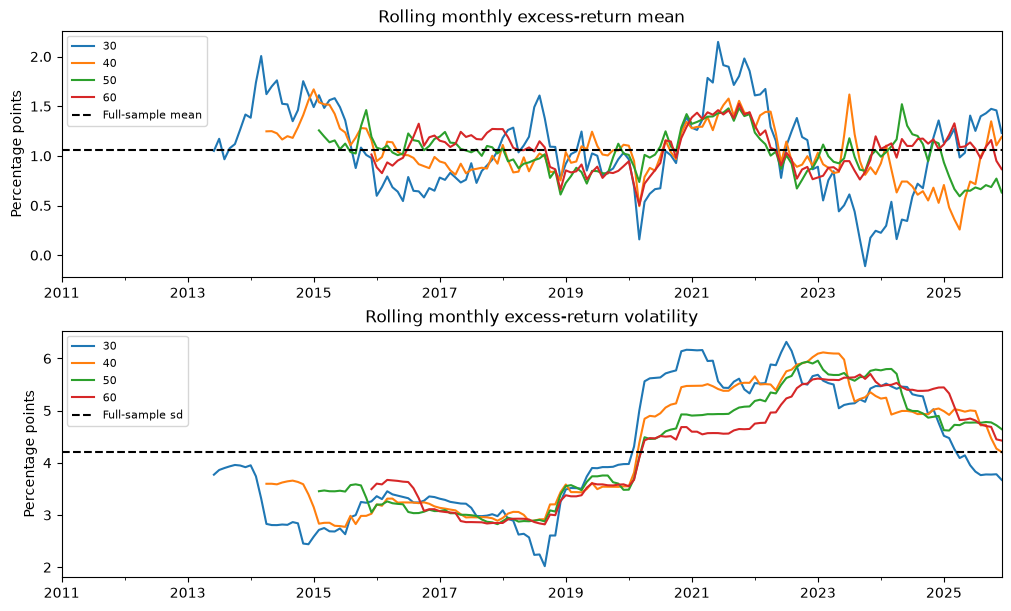

In [4]:
# Each column represents a different rolling window length in months.
windows = [30, 40, 50, 60]
# Require full windows: the first w - 1 observations have no estimate.
rolling_means = pd.DataFrame({w: excess.rolling(w, min_periods=w).mean() for w in windows})
# Use the sample standard deviation (ddof=1) to measure volatility.
rolling_sds = pd.DataFrame({w: excess.rolling(w, min_periods=w).std(ddof=1) for w in windows})

fig, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
(100 * rolling_means).plot(ax=axes[0])
(100 * rolling_sds).plot(ax=axes[1])
# Add full-sample statistics as visual references.
axes[0].axhline(100 * excess.mean(), color="black", ls="--", label="Full-sample mean")
axes[1].axhline(100 * excess.std(ddof=1), color="black", ls="--", label="Full-sample sd")
for ax, title in zip(axes, ["Rolling monthly excess-return mean", "Rolling monthly excess-return volatility"]):
    ax.set(title=title, ylabel="Percentage points", xlabel="")
    ax.legend(fontsize=8)
plt.show()

Shorter windows react faster and fluctuate more. Longer windows smooth the estimates but adjust
more slowly. Full-sample lines summarise the completed period and use future observations relative
to early dates. They provide visual references; they were not available at those earlier dates.

## Conventional rolling inference

Within each 60-month window, a two-sided t-test evaluates the null hypothesis that the
mean excess return is zero, $H_0:\mu=0$. The standard error of the sample mean is
estimated as $s_t/\sqrt{60}$, giving:

$$
t_t=\frac{\bar R_t^e}{s_t/\sqrt{60}},\qquad
p_t=2\Pr(T_{59}\ge |t_t|).
$$

The Student reference distribution has 59 degrees of freedom. It is exact for independent,
identically distributed Normal observations. Dependence or changing dispersion can make
$s/\sqrt n$ inappropriate, so this conventional test should be interpreted with its assumptions.

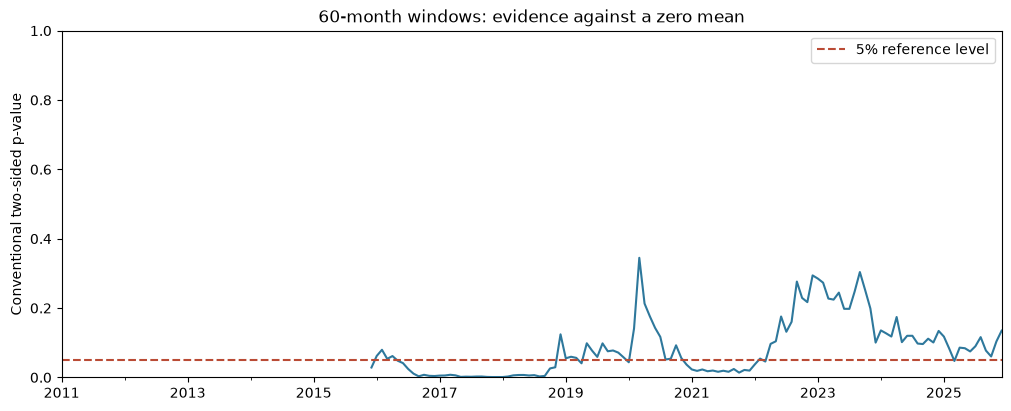

,mean (%),t,p
date,,,
2025-01-31,1.1160,1.5878,0.1177
2025-02-28,1.2112,1.7607,0.0835
2025-03-31,1.3275,2.0263,0.0473
2025-04-30,1.0868,1.7470,0.0858
2025-05-31,1.0950,1.7572,0.0841
2025-06-30,1.1352,1.8136,0.0748
2025-07-31,1.0710,1.7245,0.0898
2025-08-31,0.9747,1.5947,0.1161
2025-09-30,1.0918,1.7974,0.0774


In [5]:
# Reuse the 60-month estimates; the first 59 dates have no complete window.
window = 60
mean60 = rolling_means[window]
sd60 = rolling_sds[window]
# Divide the mean excess return by its estimated standard error.
t_values = mean60 / (sd60 / np.sqrt(window))
# Use both tails of the Student distribution with w - 1 degrees of freedom.
p_values = pd.Series(2 * stats.t.sf(np.abs(t_values), df=window - 1), index=excess.index)

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
p_values.plot(ax=ax, color="#2e789c")
ax.axhline(0.05, color="#ba4b35", ls="--", label="5% reference level")
ax.set(ylim=(0, 1), ylabel="Conventional two-sided p-value", xlabel="",
       title="60-month windows: evidence against a zero mean")
ax.legend()
plt.show()

# Collect only dates with a complete window and display the final 12 estimates.
rolling_inference = pd.DataFrame({
    "mean (%)": 100 * mean60, "t": t_values, "p": p_values,
}).dropna(subset=["p"])
display(rolling_inference.tail(12).round(4))

Adjacent 60-month windows share 59 observations, making their estimates and p-values strongly
related. Searching repeatedly for significance adds a multiple-testing concern. A small p-value
does not forecast a positive future premium. Daily return non-Normality and the distribution
of a monthly sample mean are different objects; an approximation for the latter depends on
moments and dependence, rather than on a sample-size threshold alone.